# 05 - ICH Triage and Visualization

**Purpose.** Aggregate slice-level probabilities of the selected model into study-level triage scores, report subtype probabilities and high-risk slices, produce Grad-CAM explanations, and (optionally) run competition-test inference.

**Requires (inputs).** Outputs of notebooks 00 and 01/02 (same MODE).

**Produces (outputs, under `/kaggle/working/rsna_ich_artifacts/<MODE>/`).** `triage/study_level_<agg>.csv`, `triage/study_metrics.csv`, `triage/triage_table_test.csv`, `triage/figures/*`, optional `submission/submission.csv`.

> Research software. Outputs are model predictions for a research study and **not** clinical diagnoses.
> Results in this notebook are only valid for the MODE they were produced in (`smoke` results check correctness and say nothing about performance).

In [1]:
# ==== Setup: locate the project code and make `src` importable ====================================
# Works on Kaggle (project code attached as a Dataset, possibly nested after zip extraction) and locally.
import os, sys, importlib
from pathlib import Path

def find_project_root(max_depth: int = 5) -> Path:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file() and (p / "configs" / "data_config.yaml").is_file()
    cands = []
    if os.environ.get("RSNA_ICH_PROJECT_ROOT"):
        cands.append(Path(os.environ["RSNA_ICH_PROJECT_ROOT"]))
    cands += [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/RSNA_ICH_Research")]
    for c in cands:
        if ok(c):
            return c.resolve()
    for base in (Path("/kaggle/input"), Path("/kaggle/working")):
        if not base.exists():
            continue
        stack = [(base, 0)]
        while stack:
            d, depth = stack.pop()
            if ok(d):
                return d.resolve()
            if depth < max_depth:
                try:
                    stack += [(p, depth + 1) for p in d.iterdir() if p.is_dir() and not p.name.startswith("stage_2_")]
                except OSError:
                    pass
    raise FileNotFoundError(
        "Project code not found. On Kaggle: 'Add Input' -> the dataset containing RSNA_ICH_Research "
        "(with src/ and configs/). Locally: run the notebook from RSNA_ICH_Research/notebooks or set "
        "the RSNA_ICH_PROJECT_ROOT environment variable.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in ["src", "src.utils.context", "src.data", "src.models", "src.quantum", "src.training", "src.evaluation"]:
    importlib.import_module(_m)  # fails loudly here if a dependency is missing
import src
print(f"Project root: {PROJECT_ROOT}  |  src version {src.__version__}")

Project root: /kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research  |  src version 1.0.0


In [2]:
# ==== Configuration ================================================================================
# MODE: "smoke" (correctness check, minutes) | "pilot" (representative subset) | "full" (largest feasible).
MODE = "pilot"
# Optional per-config overrides without editing YAML, e.g. {"transformer": {"train": {"epochs": 2}}}
OVERRIDES = {}
import json
if os.environ.get("RSNA_ICH_OVERRIDES_JSON"):          # test hook used by tools/run_notebooks_synthetic.py
    OVERRIDES = json.loads(os.environ["RSNA_ICH_OVERRIDES_JSON"])
MODE = os.environ.get("RSNA_ICH_MODE", MODE)

from src.utils.context import ProjectContext
ctx = ProjectContext(PROJECT_ROOT, MODE, OVERRIDES)
print(ctx.describe())
print("Installed packages:", ctx.runtime.packages)
ctx.save_run_info("05_triage")

ProjectContext(mode=pilot, root=/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research, output=/kaggle/working/rsna_ich_artifacts/pilot)
  GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.8 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Installed packages: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/run_info/05_triage.json')

In [3]:
# ==== Unpack experiments from zipped notebook outputs (Kaggle zips outputs with many files) ====
import glob, zipfile, shutil
key = f"{MODE}/experiments/"
dst_root = ctx.output_root / "experiments"
zips = [z for pat in ["/kaggle/input/*/_output_.zip", "/kaggle/input/*/*/_output_.zip",
                      "/kaggle/input/*/*/*/_output_.zip", "/kaggle/input/*/*/*/*/_output_.zip"]
        for z in glob.glob(pat)]
print("Zipped inputs:", zips)
n = 0
for z in zips:
    with zipfile.ZipFile(z) as zf:
        for name in zf.namelist():
            if key not in name or name.endswith("/") or name.endswith("last.pt"):
                continue
            rel = name.split(key, 1)[1]
            if not rel.startswith(("A_", "B_", "H_")):
                continue
            out = dst_root / rel
            if out.exists():
                continue
            out.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(name) as src, open(out, "wb") as f:
                shutil.copyfileobj(src, f)
            n += 1
print(f"Extracted {n} files")
print(sorted(p.name for p in dst_root.iterdir() if p.is_dir()))

Zipped inputs: ['/kaggle/input/notebooks/mehulkhannaa/01-classical-transformer-benchmark/_output_.zip']
Extracted 62 files
['A_deit_small', 'A_maxvit_tiny', 'A_swin_tiny', 'H_maxvit_tiny_brain3']


In [4]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import LABELS
from src.utils.io import atomic_write_json, atomic_save_dataframe, read_json, dataframe_to_markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

> **Not a clinical tool.** Study-level outputs are aggregated model predictions on retrospective research data. They have not been clinically validated and must not be used for diagnosis or patient management.

In [5]:
from src.training.experiment import select_best_by_validation, load_model_from_result
from src.evaluation.predictions import load_predictions
manifest, man_info = ctx.manifest()
best = select_best_by_validation(ctx, ("A_", "B_"))
if best is None:
    raise RuntimeError("No trained image model found for this MODE (attach notebook 01/02 output).")
print("Selected (validation):", best["experiment_id"], round(best["val_metrics"]["macro_roc_auc"], 4))
d = Path(best["_dir"]); tri_dir, fig_dir = ctx.dir("triage"), ctx.dir("triage", "figures")
pv, _ = load_predictions(d / "predictions_val.parquet", man_info["manifest_hash"])
pt, _ = load_predictions(d / "predictions_test.parquet", man_info["manifest_hash"])
for df in (pv, pt):
    if "study_uid" not in df or df["study_uid"].isna().all():
        df.drop(columns=[c for c in ("study_uid", "patient_id", "slice_rank") if c in df], inplace=True)
        df[["study_uid", "patient_id", "slice_rank"]] = manifest.set_index("image_id").loc[df["image_id"], ["study_uid", "patient_id", "slice_rank"]].to_numpy()

Selected (validation): A_maxvit_tiny 0.9577


## 1. Study-level aggregation (threshold chosen on validation studies, applied to test studies)

In [6]:
from src.evaluation.study_aggregation import aggregate_studies, AGGREGATORS, triage_table, high_risk_slices
from src.evaluation.metrics import compute_metrics
from src.evaluation.thresholds import select_thresholds
from src.evaluation.statistics import bootstrap_table
N_BOOT = {"smoke": 50, "pilot": 300, "full": 1000}[MODE]
rows = {}
for agg in AGGREGATORS:
    sv, st = aggregate_studies(pv, agg), aggregate_studies(pt, agg)
    P = lambda s: s[[f"prob_{l}" for l in LABELS]].to_numpy(); T = lambda s: s[[f"target_{l}" for l in LABELS]].to_numpy()
    ts = select_thresholds(T(sv), P(sv), split="val", manifest_hash=man_info["manifest_hash"], experiment_id=f"study_{agg}")
    m = compute_metrics(T(st), P(st), ts.thresholds, threshold_source="validation studies (frozen)")
    ci = bootstrap_table(T(st), P(st), st["patient_id"].to_numpy(), ["macro_auc", "auc:any"], n_boot=N_BOOT).set_index("metric")
    rows[agg] = {"n_test_studies": len(st), "macro_auc": m.aggregate["macro_roc_auc"], "macro_auc_ci": (ci.loc["macro_auc", "ci_low"], ci.loc["macro_auc", "ci_high"]),
                 "any_auc": m.aggregate.get("any_roc_auc"), "any_auc_ci": (ci.loc["auc:any", "ci_low"], ci.loc["auc:any", "ci_high"]),
                 "any_sensitivity": m.per_label.set_index("label").loc["any", "sensitivity"],
                 "any_specificity": m.per_label.set_index("label").loc["any", "specificity"], "any_threshold": ts.thresholds["any"]}
    atomic_save_dataframe(st, tri_dir / f"study_level_{agg}_test.csv")
study_metrics = pd.DataFrame(rows).T; display(study_metrics)
atomic_save_dataframe(study_metrics.reset_index(names="aggregation"), tri_dir / "study_metrics.csv")
if man_info.get("partial_header_scan"):
    print("NOTE: partial header scan (smoke) - studies are incomplete, so study-level numbers are not meaningful.")

,n_test_studies,macro_auc,macro_auc_ci,any_auc,any_auc_ci,any_sensitivity,any_specificity,any_threshold
max,277,0.931927,"(0.9064260094276733, 0.9496866260097185)",0.968061,"(0.9386125236905963, 0.9897960509664776)",0.905172,0.931677,0.898767
mean,277,0.920773,"(0.8912112816160025, 0.947716785516445)",0.950096,"(0.9134679488526152, 0.9789128947844545)",0.775862,0.956522,0.245801
top3_mean,277,0.935027,"(0.9103292636774228, 0.95375290551131)",0.966106,"(0.9368790020762534, 0.9883748945055585)",0.896552,0.962733,0.836719
noisy_or,277,0.923534,"(0.8961723982470272, 0.946835738216877)",0.947285,"(0.9137190828221687, 0.9766522607517804)",0.905172,0.931677,0.999975


## 2. Triage table and high-risk slices (max aggregation; validation-selected study threshold)

In [7]:
AGG = "max"
st = aggregate_studies(pt, AGG)
tt = triage_table(st, float(study_metrics.loc[AGG, "any_threshold"]))
display(tt.head(10)[["study_uid", "n_slices", "prob_any", "flag_any", "most_likely_subtype", *[f"prob_{l}" for l in LABELS[:-1]], "target_any"]].round(3))
atomic_save_dataframe(tt, tri_dir / "triage_table_test.csv")
for s in tt["study_uid"].head(2):
    print("Study", s); display(high_risk_slices(pt, s, top_k=5).round(3))

,study_uid,n_slices,prob_any,flag_any,most_likely_subtype,prob_epidural,prob_intraparenchymal,prob_intraventricular,prob_subarachnoid,prob_subdural,target_any
0,ID_1a3888227a,28,0.997,True,intraparenchymal,0.536,0.981,0.974,0.980,0.859,1.0
1,ID_df4a6255c1,39,0.996,True,intraparenchymal,0.422,0.960,0.931,0.950,0.766,1.0
2,ID_d467f74f67,32,0.996,True,intraventricular,0.398,0.963,0.982,0.963,0.931,1.0
3,ID_ec48e3e05f,34,0.996,True,subarachnoid,0.775,0.961,0.958,0.983,0.873,1.0
4,ID_49b47a0074,40,0.996,True,subdural,0.760,0.932,0.553,0.903,0.986,1.0
5,ID_41d6fe610e,32,0.996,True,intraparenchymal,0.501,0.979,0.974,0.969,0.820,1.0
6,ID_5920f1d5d2,37,0.996,True,intraparenchymal,0.641,0.984,0.932,0.935,0.851,1.0
7,ID_5adbd93306,28,0.995,True,intraventricular,0.295,0.982,0.983,0.915,0.796,1.0
8,ID_bcab9a1761,34,0.995,True,subdural,0.862,0.930,0.862,0.948,0.960,1.0
9,ID_5b133aa2c0,28,0.995,True,intraparenchymal,0.262,0.978,0.971,0.968,0.531,1.0


Study ID_1a3888227a


,image_id,slice_rank,prob_epidural,prob_intraparenchymal,prob_intraventricular,prob_subarachnoid,prob_subdural,prob_any
0,ID_64266f428,10,0.480,0.972,0.787,0.889,0.539,0.997
1,ID_d9b6fc0c8,11,0.517,0.981,0.935,0.841,0.504,0.997
2,ID_e25a5459f,12,0.415,0.784,0.963,0.799,0.646,0.994
3,ID_dd720c710,13,0.452,0.846,0.972,0.880,0.610,0.995
4,ID_ad2dfbb6a,15,0.417,0.713,0.955,0.912,0.755,0.994


Study ID_df4a6255c1


,image_id,slice_rank,prob_epidural,prob_intraparenchymal,prob_intraventricular,prob_subarachnoid,prob_subdural,prob_any
0,ID_0e79ea880,20,0.148,0.888,0.931,0.837,0.611,0.994
1,ID_0f74e6499,21,0.230,0.939,0.784,0.853,0.700,0.996
2,ID_00e57ae63,22,0.289,0.960,0.666,0.784,0.657,0.995
3,ID_7a7c6b55e,23,0.234,0.951,0.338,0.852,0.662,0.991
4,ID_1b52411fd,24,0.326,0.953,0.300,0.816,0.691,0.989


## 3. Grad-CAM explanations (qualitative; not segmentation, not validated localisation)

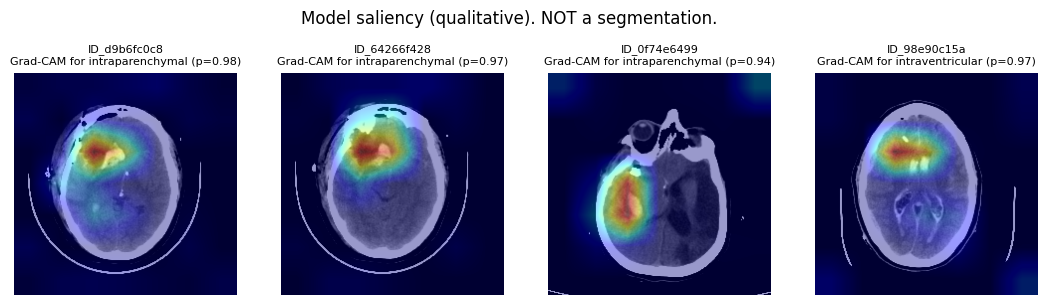

In [8]:
from src.evaluation.explainability import GradCAM, default_cam_target
from src.evaluation.visualization import overlay_cam
from src.data.dataset import RSNASliceDataset
from src.data.preprocessing import PreprocessConfig
model = load_model_from_result(best, man_info["manifest_hash"])
pp = PreprocessConfig.from_dict(best["config"]["preprocess"])
pos = pt[pt["target_any"] >= 0.5].sort_values("prob_any", ascending=False).head(4)
if len(pos):
    layer, layout, prefix = default_cam_target(model)
    cam = GradCAM(model, layer, layout, prefix)
    ds = RSNASliceDataset(pos[["image_id"]], ctx.rsna.train_dir, pp)
    raw = RSNASliceDataset(pos[["image_id"]], ctx.rsna.train_dir, {**best["config"]["preprocess"], "normalization": "none"})
    fig, axes = plt.subplots(1, len(ds), figsize=(3.3 * len(ds), 3.6))
    dev = next(model.parameters()).device
    for i in range(len(ds)):
        row = pos.iloc[i]
        lab = max(range(5), key=lambda j: row[f"prob_{LABELS[j]}"])
        heat = cam(ds[i]["image"][None].to(dev), lab)[0].numpy()
        overlay_cam(raw[i]["image"][0].numpy(), heat, np.atleast_1d(axes)[i],
                    title=f"{row['image_id']}\nGrad-CAM for {LABELS[lab]} (p={row[f'prob_{LABELS[lab]}']:.2f})")
    cam.remove(); fig.suptitle("Model saliency (qualitative). NOT a segmentation."); fig.savefig(fig_dir / "gradcam_examples.png", dpi=120); plt.show()

## 4. Optional: competition-test inference (`stage_2_test`, no labels) -> submission file

In [9]:
RUN_COMPETITION_INFERENCE = False
RUN_COMPETITION_INFERENCE = RUN_COMPETITION_INFERENCE or os.environ.get("RSNA_ICH_RUN_COMPETITION_INFERENCE") == "1"  # test hook
MAX_TEST_IMAGES = {"smoke": 64, "pilot": None, "full": None}[MODE]
if RUN_COMPETITION_INFERENCE:
    from src.data.csv_parser import parse_submission_ids
    from src.data.dataset import make_loader
    from src.training.trainer import predict
    from src.evaluation.predictions import predictions_frame
    from src.evaluation.submission import make_submission, save_submission
    ids = parse_submission_ids(ctx.rsna.sample_submission)
    if MAX_TEST_IMAGES: ids = ids.head(MAX_TEST_IMAGES)
    dl = make_loader(RSNASliceDataset(ids, ctx.rsna.test_dir, pp), 64, False, 2)
    out = predict(model, dl, next(model.parameters()).device)
    sub = make_submission(predictions_frame(out["image_ids"], out["probs"]), ctx.rsna.sample_submission)
    print("images with no prediction (filled with 0.5):", sub.attrs["filled"], "| undecodable:", int((~out["ok"]).sum()))
    save_submission(sub, ctx.dir("submission") / "submission.csv"); display(sub.head())
else:
    print("Competition inference disabled (set RUN_COMPETITION_INFERENCE = True).")

Competition inference disabled (set RUN_COMPETITION_INFERENCE = True).
